# Cohort-Wide Cross-Model Benchmark Comparison

This notebook performs a centralized cohort-level comparison across all 9 model configurations: 
1. Logistic Regression (FCz-theta)
2. Logistic Regression (Oz-alpha)
3. Riemannian TS-LDA
4. Experiment-based Experiment-Guided Config
5. EEGNet Agnostic
6. EEGNet Clustering
7. ST-GNN
8. ST-EEGFormer
9. LaBraM

We load the cached cross-validation metrics for each model, plot comparative boxplots, connect subject trajectories, run pairwise Wilcoxon signed-rank tests with false discovery rate (FDR) correction, and generate a summary ranking table.

In [38]:
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon
from mne.stats import fdr_correction

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()
SRC_DIR = (
    Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if "google.colab" in sys.modules
    else NOTEBOOK_DIR.parent.parent / "src"
)

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import detect_project_paths, get_task_config

warnings.filterwarnings("ignore")
RANDOM_SEED = 42

In [39]:
# Unified Environment Setup (Local, Colab, Kaggle)
import os
import sys
from pathlib import Path

IS_COLAB = 'google.colab' in sys.modules

if IS_COLAB:
    print('Detected Google Colab environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
    from google.colab import drive
    drive.mount('/content/drive')

# Locate workspace source directory
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IS_COLAB:
    SRC_DIR = Path('/content/drive/MyDrive/TFG_Nils_2026/03_Codi')
else:
    SRC_DIR = NOTEBOOK_DIR.parent

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f'Using source directory: {SRC_DIR}')

Using source directory: c:\Users\nils\Documents\Universitat\TFG\src


In [40]:
# TASK CONFIGURATION: Change to "im_vs_ip" to run comparison for Task 2
TASK_TAG = "c_vs_ip"
TASK_TAG_DISPLAY = TASK_TAG.split("_vs_")[0].upper() + " vs " + TASK_TAG.split("_vs_")[1].upper()

paths = detect_project_paths("cross_model_comparison", in_colab=IN_COLAB)
task = get_task_config(TASK_TAG, paths.analysis_root)

print(f"Project directory: {paths.project_dir}")
print(f"Analysis root: {paths.analysis_root}")
print(f"Selected task: {task.name} ({task.class_0} vs {task.class_1})")

Project directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Analysis root: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
Selected task: c_vs_i (Congruent vs Incongruent_Pure)


In [41]:
import mne
import torch
from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    get_epochs_grid,
    BinaryTaskConfig,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
    load_fused_band_dataset,
    FusedBandSpec,
    chronological_group_labels,
    stratified_group_splits,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
)
from br_analysis.torch_models import (
    STGNNChebConv,
    EEGNet,
)
from br_analysis.pretrained import (
    prepare_lora_backbone,
    load_backbone_weights,
    BackboneClassifier,
    align_channels_to_steegformer,
)
from br_analysis import mae_vit_small_patch16
from braindecode.models import InterpolatedLaBraM

# ── TASK CONFIGURATION ────────────────────────────────────────────────────────
# Change TASK_TAG to "im_vs_ip" to run the Task 2 comparison instead
TASK_TAG = "c_vs_ip"
paths = detect_project_paths("cross_model_comparison")
task = get_task_config(TASK_TAG, paths.analysis_root)

# ── subject list ──────────────────────────────────────────────────────────────
subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Working Paths:")
print("  Cache:", paths.cache_dir)
print("  Tables:", paths.tables_dir)
print("  Figures:", paths.figures_dir)
print(f"Task: {TASK_TAG_DISPLAY}  |  Subjects: {len(subject_ids)}")

# ── Define model directory paths ──────────────────────────────────────────────
task_name_lc = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
if task_name_lc == "c_vs_ip":
    lr_dir = "c_vs_i"
    riemann_dir = "c_vs_i_riemann"
    eegnet_dir = "c_vs_i_eegnet"
    stgnn_dir = "c_vs_i_stgnn"
    steegformer_dir = "c_vs_i_steegformer"
    labram_dir = "c_vs_i_labram"
else:
    lr_dir = "im_vs_ip"
    riemann_dir = "im_vs_ip_riemann"
    eegnet_dir = "im_vs_ip_eegnet"
    stgnn_dir = "im_vs_ip_stgnn"
    steegformer_dir = "im_vs_ip_steegformer"
    labram_dir = "im_vs_ip_labram"

print(
    f"Model Directories: LR={lr_dir}, Riemann={riemann_dir}, EEGNet={eegnet_dir}, ST-GNN={stgnn_dir}, ST-EEGFormer={steegformer_dir}, LaBraM={labram_dir}"
)

Working Paths:
  Cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\cache
  Tables: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\tables
  Figures: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\figures
Task: C vs IP  |  Subjects: 30
Model Directories: LR=c_vs_i, Riemann=c_vs_i_riemann, EEGNet=c_vs_i_eegnet, ST-GNN=c_vs_i_stgnn, ST-EEGFormer=c_vs_i_steegformer, LaBraM=c_vs_i_labram


## Cohort Accuracies Comparison (Boxplot & Stripplot)

We visualize the distribution of classification accuracies across subjects for each of the 8 model variants.

In [42]:
# ── Build df_merged: per-subject × per-model balanced accuracy table ─────────────────
# Loads the per-fold CV cache files produced by each model notebook and
# computes the mean balanced accuracy per subject, for every available model.
# Models whose cache files do not exist are simply skipped.

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import balanced_accuracy_score

OOF_CACHE_VERSION = "stratified_group_kfold_holdout_v1"


def oof_cache_status(path):
    if not path.exists():
        return False, "missing"
    try:
        with np.load(path, allow_pickle=True) as data:
            if "_cache_version" not in data:
                return False, "legacy cache without _cache_version"
            version = str(np.asarray(data["_cache_version"]).item())
            if version != OOF_CACHE_VERSION:
                return False, f"cache version {version} != {OOF_CACHE_VERSION}"
            strategy = str(np.asarray(data["_cv_strategy"]).item()) if "_cv_strategy" in data else "unknown"
            if strategy != "stratified_group_kfold_development_only":
                return False, f"unexpected cv strategy {strategy}"
    except Exception as exc:
        return False, f"could not read metadata: {exc}"
    return True, "ok"


if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

# ── file names (mirrors comp_roc_pr_code) ────────────────────────────────────
if "c_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_c_vs_i_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_c_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_c_vs_ip_eegnet_clustering.npz"
    svc_clust_file = "oof_predictions_c_vs_ip_svc_clustering.npz"
    stgnn_file = "oof_predictions_c_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_c_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_c_vs_ip_labram.npz"
    experiment_guided_file = "oof_predictions_c_vs_ip_experiment_guided.npz"
    experiment_guided_dir = "experiment_guided_config_c_ip"
elif "im_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_im_vs_ip_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_im_vs_ip_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_im_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_im_vs_ip_eegnet_clustering.npz"
    svc_clust_file = "oof_predictions_im_vs_ip_svc_clustering.npz"
    stgnn_file = "oof_predictions_im_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_im_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_im_vs_ip_labram.npz"
    experiment_guided_file = "oof_predictions_im_vs_ip_experiment_guided.npz"
    experiment_guided_dir = "experiment_guided_config_im_ip"

cache_paths_acc = {
    "LR_theta": paths.analysis_root / lr_dir / "cache" / lr_file,
    "LR_alpha": paths.analysis_root / lr_dir / "cache" / lr_file,
    "Riemann": paths.analysis_root / riemann_dir / "cache" / riemann_file,
    "Experiment_Guided": paths.analysis_root / experiment_guided_dir / "cache" / experiment_guided_file,
    "EEGNet_Agnostic": paths.cache_dir / eegnet_agn_file,
    "EEGNet_Clustering": paths.cache_dir / eegnet_clust_file,
    "SVC_Clustering": paths.cache_dir / svc_clust_file,
    "ST_GNN": paths.cache_dir / stgnn_file,
    "ST_EEGFormer": paths.cache_dir / steeg_file,
    "LaBraM": paths.cache_dir / labram_file,
}


# ── prob / y_true key helpers ─────────────────────────────────────────────────
def _prob_key(model_name, sub):
    if model_name == "LR_theta":
        return f"{sub}_FCz-theta_prob"
    if model_name == "LR_alpha":
        return f"{sub}_Oz-alpha_prob"
    if model_name == "Riemann":
        return f"{sub}_fused_prob"
    return f"{sub}_prob"


# ── build the per-subject table ───────────────────────────────────────────────
rows = []
for sub in subject_ids:
    row = {"subject": sub}
    for model_name, cache_file in cache_paths_acc.items():
        fresh, reason = oof_cache_status(cache_file)
        if not fresh:
            print(f"[SKIP] {model_name}: {reason} ({cache_file.name})")
            continue
        with np.load(cache_file, allow_pickle=True) as data:
            yt_key = f"{sub}_y_true"
            yp_key = _prob_key(model_name, sub)
            if yt_key in data and yp_key in data:
                y_true = data[yt_key]
                y_prob = data[yp_key]
                valid = ~np.isnan(y_prob)
                if valid.any():
                    y_pred = (y_prob[valid] >= 0.5).astype(int)
                    row[model_name] = balanced_accuracy_score(y_true[valid], y_pred)
    rows.append(row)

df_merged = pd.DataFrame(rows).set_index("subject").reset_index()
present_models = [c for c in df_merged.columns if c != "subject"]
df_merged = df_merged.dropna(subset=present_models, how="all")
subject_ids = df_merged["subject"].tolist()

present_models = [c for c in df_merged.columns if c != "subject"]
print(f"df_merged built: {len(df_merged)} subjects × {len(present_models)} models")
print(f"  Models present: {present_models}")

df_merged built: 24 subjects × 10 models
  Models present: ['LR_theta', 'LR_alpha', 'Riemann', 'Experiment_Guided', 'EEGNet_Agnostic', 'EEGNet_Clustering', 'SVC_Clustering', 'ST_GNN', 'ST_EEGFormer', 'LaBraM']


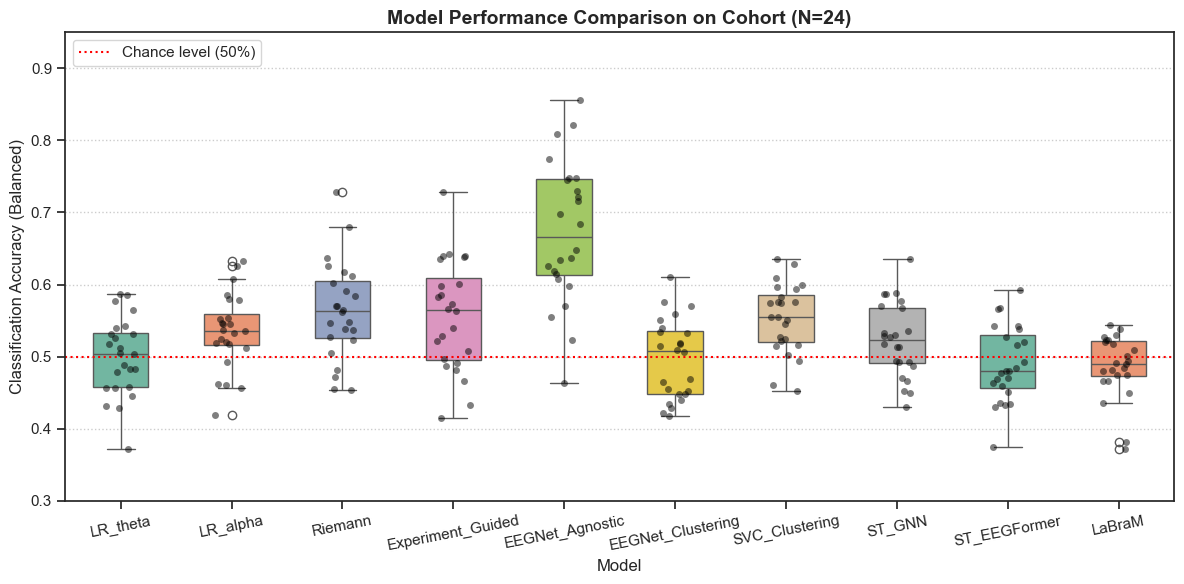

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# ── Guard: ensure derived variables exist if this cell runs standalone ─────────
if "lr_dir" not in dir():
    if "c_vs_ip" in TASK_TAG:
        lr_dir = "c_vs_i"
        riemann_dir = "c_vs_i_riemann"
    else:
        lr_dir = "im_vs_ip"
        riemann_dir = "im_vs_ip_riemann"
if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

model_cols = [
    "LR_theta",
    "LR_alpha",
    "Riemann",
    "Experiment_Guided",
    "EEGNet_Agnostic",
    "EEGNet_Clustering",
    "SVC_Clustering",
    "ST_GNN",
    "ST_EEGFormer",
    "LaBraM",
]
model_cols = [c for c in model_cols if c in df_merged.columns]
df_long = df_merged.melt(id_vars="subject", value_vars=model_cols, var_name="Model", value_name="Balanced Accuracy")

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="Model", y="Balanced Accuracy", palette="Set2", width=0.5)
sns.stripplot(data=df_long, x="Model", y="Balanced Accuracy", color="black", alpha=0.5, size=5, jitter=0.15)
plt.axhline(0.5, color="red", linestyle=":", label="Chance level (50%)")
plt.title(f"Model Performance Comparison on Cohort (N={len(df_merged)})", fontsize=14, fontweight="bold")
plt.ylabel("Classification Accuracy (Balanced)")
plt.xticks(rotation=11)
plt.ylim(0.3, 0.95)
plt.legend(loc="upper left")
plt.grid(True, axis="y", linestyle=":")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_comparison_boxplot_{TASK_TAG}.png", dpi=200, bbox_inches="tight")

## Connected Subject Accuracies

We trace the accuracy of each individual subject across the different model categories to examine cohort consistency.

In [44]:
for model_name in df_merged.columns:
    if model_name == "subject":
        continue
    acc_values = df_merged[model_name].dropna()
    mean_acc = acc_values.mean()
    std_acc = acc_values.std()
    print(f"{model_name}: {mean_acc:.3f} ± {std_acc:.3f}")

LR_theta: 0.500 ± 0.054
LR_alpha: 0.535 ± 0.053
Riemann: 0.564 ± 0.068
Experiment_Guided: 0.557 ± 0.077
EEGNet_Agnostic: 0.673 ± 0.098
EEGNet_Clustering: 0.497 ± 0.056
SVC_Clustering: 0.553 ± 0.049
ST_GNN: 0.523 ± 0.052
ST_EEGFormer: 0.489 ± 0.053
LaBraM: 0.486 ± 0.044


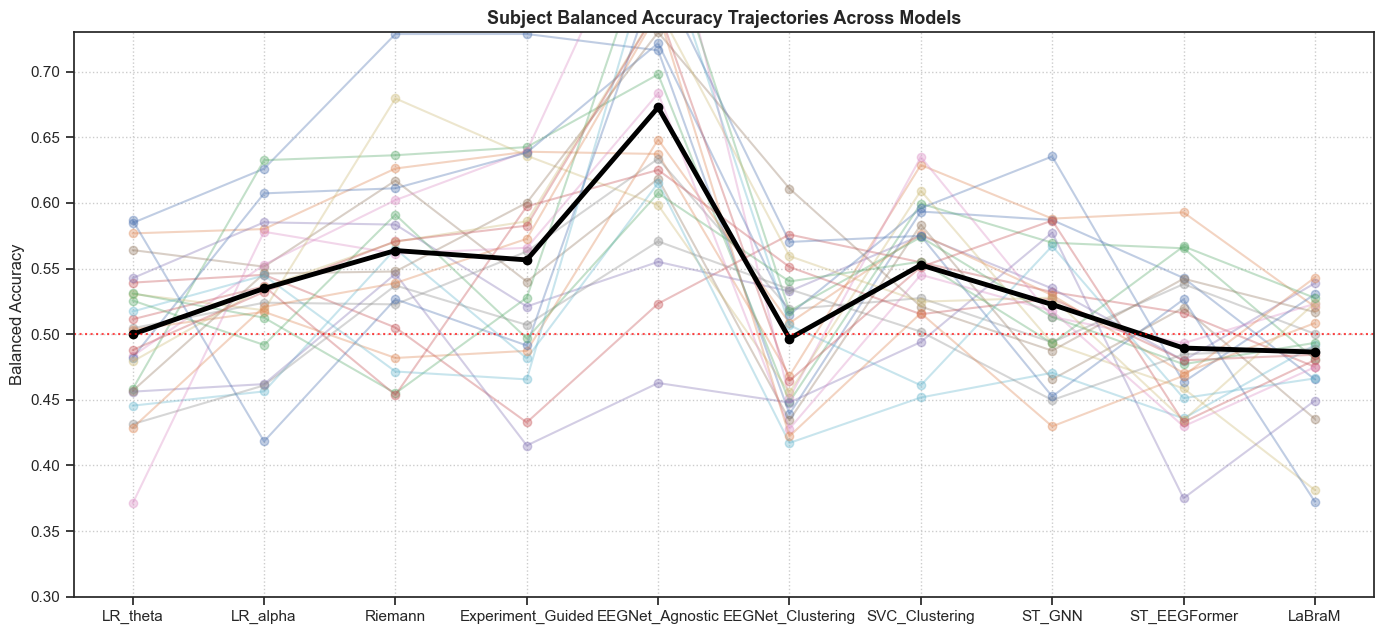

In [45]:
plt.figure(figsize=(14, 6.5))
for i, row in df_merged.iterrows():
    plt.plot(model_cols, row[model_cols].values, "o-", alpha=0.35, label=row["subject"])

# Plot the group mean trajectory
mean_trajectory = df_merged[model_cols].mean(axis=0).values
plt.plot(model_cols, mean_trajectory, "o-", color="black", linewidth=3.5, label="GROUP MEAN")

plt.axhline(0.5, color="red", linestyle=":", alpha=0.7)
plt.title("Subject Balanced Accuracy Trajectories Across Models", fontsize=13, fontweight="bold")
plt.ylabel("Balanced Accuracy")
plt.ylim(0.3, 0.73)
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_subject_trajectories_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

## Cohort ROC and Precision-Recall Curves

To evaluate discrimination globally, we aggregate out-of-fold predictions across all selected subjects. Models without available prediction caches are skipped automatically; this is especially important for the IM vs IP notebooks, where some deep-model caches may still be absent.



**OOF cache freshness.** These plots only load `oof_predictions_*.npz` files generated with the current `stratified_group_kfold_development_only` strategy. Legacy NPZ caches without `_cache_version` are skipped and must be regenerated from their source notebooks before being included here.


[OK] LR_theta: 4686 predictions loaded
[OK] LR_alpha: 4686 predictions loaded
[OK] Riemann: 4686 predictions loaded
[OK] Experiment_Guided: 4686 predictions loaded
[OK] EEGNet_Agnostic: 4686 predictions loaded
[OK] EEGNet_Clustering: 4686 predictions loaded
[OK] SVC_Clustering: 4686 predictions loaded
[OK] ST_GNN: 4686 predictions loaded
[OK] ST_EEGFormer: 4686 predictions loaded
[OK] LaBraM: 4686 predictions loaded


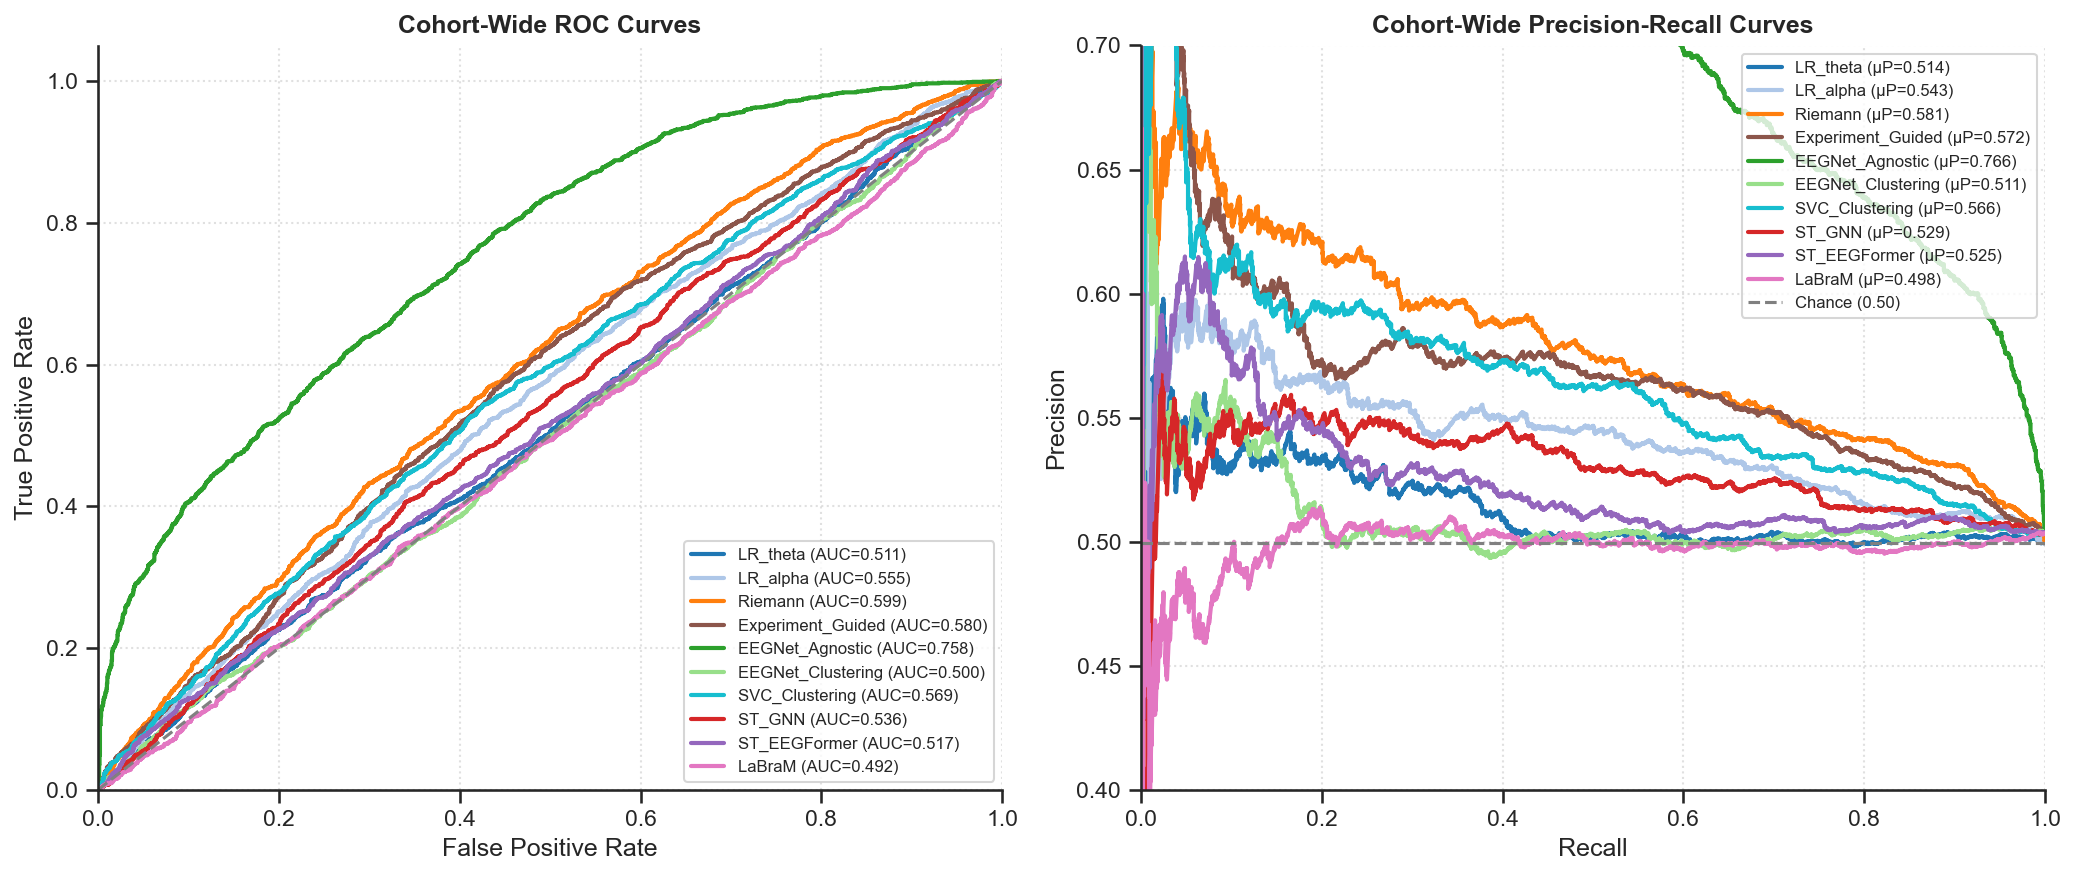

In [32]:
# ── Guard: define lr_dir / riemann_dir / subject_ids if not set upstream ────
if "lr_dir" not in dir():
    if "c_vs_ip" in TASK_TAG:
        lr_dir = "c_vs_i"
        riemann_dir = "c_vs_i_riemann"
    else:
        lr_dir = "im_vs_ip"
        riemann_dir = "im_vs_ip_riemann"
if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

OOF_CACHE_VERSION = "stratified_group_kfold_holdout_v1"


def oof_cache_status(path):
    if not path.exists():
        return False, "missing"
    try:
        with np.load(path, allow_pickle=True) as data:
            if "_cache_version" not in data:
                return False, "legacy cache without _cache_version"
            version = str(np.asarray(data["_cache_version"]).item())
            if version != OOF_CACHE_VERSION:
                return False, f"cache version {version} != {OOF_CACHE_VERSION}"
            strategy = str(np.asarray(data["_cv_strategy"]).item()) if "_cv_strategy" in data else "unknown"
            if strategy != "stratified_group_kfold_development_only":
                return False, f"unexpected cv strategy {strategy}"
    except Exception as exc:
        return False, f"could not read metadata: {exc}"
    return True, "ok"


# ── file names per task ────────────────────────────────────────────────────
if "c_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_c_vs_i_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_c_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_c_vs_ip_eegnet_clustering.npz"
    svc_clust_file = "oof_predictions_c_vs_ip_svc_clustering.npz"
    stgnn_file = "oof_predictions_c_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_c_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_c_vs_ip_labram.npz"
    experiment_guided_file = "oof_predictions_c_vs_ip_experiment_guided.npz"
    experiment_guided_dir = "experiment_guided_config_c_ip"
elif "im_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_im_vs_ip_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_im_vs_ip_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_im_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_im_vs_ip_eegnet_clustering.npz"
    svc_clust_file = "oof_predictions_im_vs_ip_svc_clustering.npz"
    stgnn_file = "oof_predictions_im_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_im_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_im_vs_ip_labram.npz"
    experiment_guided_file = "oof_predictions_im_vs_ip_experiment_guided.npz"
    experiment_guided_dir = "experiment_guided_config_im_ip"

cache_paths = {
    "LR_theta": paths.analysis_root / lr_dir / "cache" / lr_file,
    "LR_alpha": paths.analysis_root / lr_dir / "cache" / lr_file,
    "Riemann": paths.analysis_root / riemann_dir / "cache" / riemann_file,
    "Experiment_Guided": paths.analysis_root / experiment_guided_dir / "cache" / experiment_guided_file,
    "EEGNet_Agnostic": paths.cache_dir / eegnet_agn_file,
    "EEGNet_Clustering": paths.cache_dir / eegnet_clust_file,
    "SVC_Clustering": paths.cache_dir / svc_clust_file,
    "ST_GNN": paths.cache_dir / stgnn_file,
    "ST_EEGFormer": paths.cache_dir / steeg_file,
    "LaBraM": paths.cache_dir / labram_file,
}


# prob key accessor per model
def prob_key(model_name, sub):
    if model_name == "LR_theta":
        return f"{sub}_FCz-theta_prob"
    if model_name == "LR_alpha":
        return f"{sub}_Oz-alpha_prob"
    if model_name == "Riemann":
        return f"{sub}_fused_prob"
    return f"{sub}_prob"


# ── load predictions ────────────────────────────────────────────────────────
model_predictions = {}
for model_name, path in cache_paths.items():
    fresh, reason = oof_cache_status(path)
    if not fresh:
        print(f"[SKIP] {model_name}: {reason} ({path.name})")
        continue
    y_true_all, y_prob_all = [], []
    with np.load(path, allow_pickle=True) as data:
        for sub in subject_ids:
            yt_key = f"{sub}_y_true"
            yp_key = prob_key(model_name, sub)
            if yt_key in data and yp_key in data:
                yt = data[yt_key]
                yp = data[yp_key]
                valid = ~np.isnan(yp)
                y_true_all.extend(yt[valid])
                y_prob_all.extend(yp[valid])
    if y_true_all:
        model_predictions[model_name] = {
            "y_true": np.array(y_true_all),
            "y_prob": np.array(y_prob_all),
        }
        print(f"[OK] {model_name}: {len(y_true_all)} predictions loaded")

# ── palette ─────────────────────────────────────────────────────────────────
MODEL_COLORS = {
    "LR_theta": "#1f77b4",
    "LR_alpha": "#aec7e8",
    "Riemann": "#ff7f0e",
    "Experiment_Guided": "#8c564b",
    "EEGNet_Agnostic": "#2ca02c",
    "EEGNet_Clustering": "#98df8a",
    "SVC_Clustering": "#17becf",
    "ST_GNN": "#d62728",
    "ST_EEGFormer": "#9467bd",
    "LaBraM": "#e377c2",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

# ROC
ax = axes[0]
for mname, preds in model_predictions.items():
    fpr, tpr, _ = roc_curve(preds["y_true"], preds["y_prob"])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=MODEL_COLORS[mname], lw=2, label=f"{mname} (AUC={roc_auc:.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=1.5, linestyle="--")
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Cohort-Wide ROC Curves", fontsize=12, fontweight="bold")
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, linestyle=":", alpha=0.6)

# PR
ax = axes[1]
for mname, preds in model_predictions.items():
    precision, recall, _ = precision_recall_curve(preds["y_true"], preds["y_prob"])
    ap = average_precision_score(preds["y_true"], preds["y_prob"])
    ax.plot(recall, precision, color=MODEL_COLORS[mname], lw=2, label=f"{mname} (μP={ap:.3f})")
if model_predictions:
    chance = np.mean(list(model_predictions.values())[0]["y_true"])
    ax.axhline(chance, color="grey", lw=1.5, linestyle="--", label=f"Chance ({chance:.2f})")
ax.set_xlim([0, 1])
ax.set_ylim([0.4, 0.7])
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Cohort-Wide Precision-Recall Curves", fontsize=12, fontweight="bold")
ax.legend(loc="upper right", fontsize=8)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
sns.despine(fig=fig)
plt.savefig(paths.figures_dir / f"cohort_roc_pr_curves_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

## Pairwise Wilcoxon Signed-Rank Test Significance Matrix

We perform pairwise Wilcoxon signed-rank tests across subjects between all pairs of models, apply Benjamini-Hochberg False Discovery Rate (FDR) correction, and plot the resulting p-values as a significance heatmap.

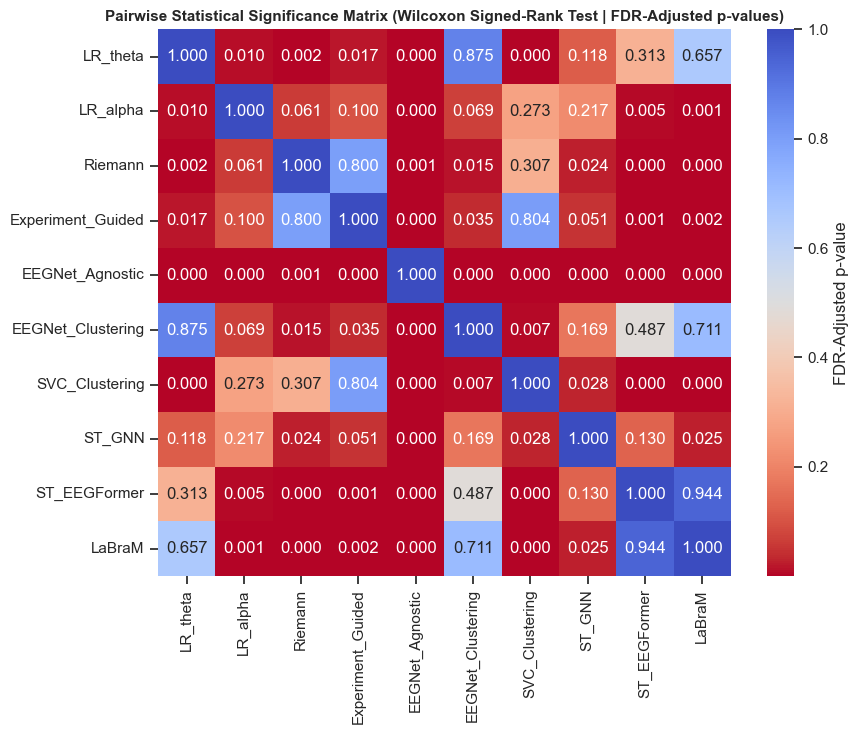

In [33]:
n_models = len(model_cols)
p_matrix = np.ones((n_models, n_models))
p_list = []
pairs = []

# Perform pairwise Wilcoxon signed-rank tests
for i in range(n_models):
    for j in range(i + 1, n_models):
        m1 = model_cols[i]
        m2 = model_cols[j]
        stat, p_val = wilcoxon(df_merged[m1], df_merged[m2])
        p_list.append(p_val)
        pairs.append((i, j))

# Apply FDR correction
reject, p_adjusted = fdr_correction(p_list, alpha=0.05, method="indep")

# Fill adjusted p-values into the matrix
for (i, j), adj_p in zip(pairs, p_adjusted):
    p_matrix[i, j] = adj_p
    p_matrix[j, i] = adj_p

# Generate Heatmap
plt.figure(figsize=(9, 7.5))
mask = np.triu(np.ones_like(p_matrix, dtype=bool), k=1)
sns.heatmap(
    p_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm_r",
    xticklabels=model_cols,
    yticklabels=model_cols,
    vmax=1.0,
    cbar_kws={"label": "FDR-Adjusted p-value"},
)
plt.title(
    "Pairwise Statistical Significance Matrix (Wilcoxon Signed-Rank Test | FDR-Adjusted p-values)",
    fontsize=11,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_pairwise_wilcoxon_matrix_{TASK_TAG}.png", dpi=220, bbox_inches="tight")
plt.show()

## Comparativa d'Explicabilitat: Topomapes i Perfil Temporal

Per comprendre quines regions cerebrals i finestres temporals fa servir cada model, comparem la seva explicabilitat espacial (topomapes) i temporal.

* **LR_theta / LR_alpha**: un únic sensor per disseny (FCz theta, Oz alpha).
* **Riemann TS-LDA**: 22 sensors (theta + alpha); importància = suma coeficients absoluts LDA per canal.
* **EEGNet Agnostic/Clustering, ST-GNN, ST-EEGFormer, LaBraM**: saliència basada en gradients (|∂logit_c1/∂x|), promediada sobre els assajos *Incongruent Pure* classificats correctament.

Si el cache d'un model no és present (p.ex. ST-EEGFormer i LaBraM si no han estat entrenats), el model s'omet automàticament i tots els plots s'adapten.

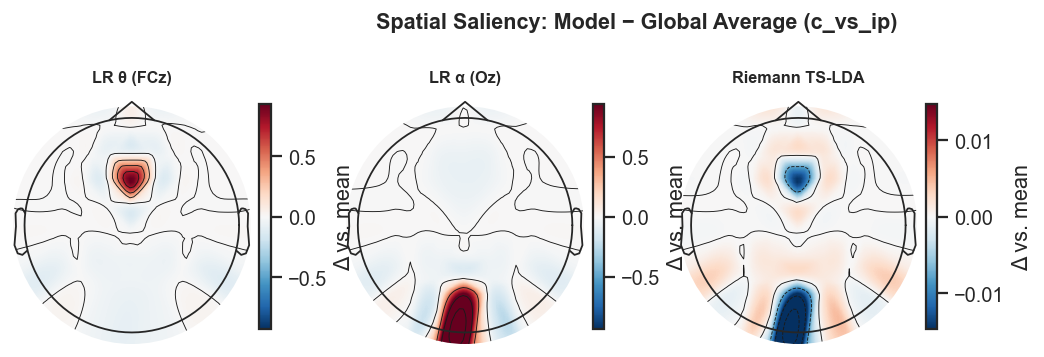

[INFO] No DL temporal saliency data available yet.


In [34]:
import numpy as np
import pandas as pd
import joblib
import mne
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

OOF_CACHE_VERSION = "stratified_group_kfold_holdout_v1"


def oof_cache_status(path):
    if not path.exists():
        return False, "missing"
    try:
        with np.load(path, allow_pickle=True) as data:
            if "_cache_version" not in data:
                return False, "legacy cache without _cache_version"
            version = str(np.asarray(data["_cache_version"]).item())
            if version != OOF_CACHE_VERSION:
                return False, f"cache version {version} != {OOF_CACHE_VERSION}"
            strategy = str(np.asarray(data["_cv_strategy"]).item()) if "_cv_strategy" in data else "unknown"
            if strategy != "stratified_group_kfold_development_only":
                return False, f"unexpected cv strategy {strategy}"
    except Exception as exc:
        return False, f"could not read metadata: {exc}"
    return True, "ok"


# ── rebuild cache_paths if this cell is run standalone (without cell 10) ───
if "lr_dir" not in dir():
    if "c_vs_ip" in TASK_TAG:
        lr_dir = "c_vs_i"
        riemann_dir = "c_vs_i_riemann"
    else:
        lr_dir = "im_vs_ip"
        riemann_dir = "im_vs_ip_riemann"
if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()
if "cache_paths" not in dir():
    if TASK_TAG == "c_vs_ip":
        _lr_f = "oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz"
        _ri_f = "oof_predictions_c_vs_i_riemann_fused.npz"
        _agn_f = "oof_predictions_c_vs_ip_eegnet_agnostic.npz"
        _clt_f = "oof_predictions_c_vs_ip_eegnet_clustering.npz"
        _svc_f = "oof_predictions_c_vs_ip_svc_clustering.npz"
        _gnn_f = "oof_predictions_c_vs_ip_stgnn.npz"
        _steg_f = "oof_predictions_c_vs_ip_steegformer.npz"
        _lab_f = "oof_predictions_c_vs_ip_labram.npz"
        _exp_f = "oof_predictions_c_vs_ip_experiment_guided.npz"
        _exp_dir = "experiment_guided_config_c_ip"
    else:
        _lr_f = "oof_predictions_im_vs_ip_FCz_theta_Oz_alpha.npz"
        _ri_f = "oof_predictions_im_vs_ip_riemann_fused.npz"
        _agn_f = "oof_predictions_im_vs_ip_eegnet_agnostic.npz"
        _clt_f = "oof_predictions_im_vs_ip_eegnet_clustering.npz"
        _svc_f = "oof_predictions_im_vs_ip_svc_clustering.npz"
        _gnn_f = "oof_predictions_im_vs_ip_stgnn.npz"
        _steg_f = "oof_predictions_im_vs_ip_steegformer.npz"
        _lab_f = "oof_predictions_im_vs_ip_labram.npz"
        _exp_f = "oof_predictions_im_vs_ip_experiment_guided.npz"
        _exp_dir = "experiment_guided_config_im_ip"
    cache_paths = {
        "LR_theta": paths.analysis_root / lr_dir / "cache" / _lr_f,
        "LR_alpha": paths.analysis_root / lr_dir / "cache" / _lr_f,
        "Riemann": paths.analysis_root / riemann_dir / "cache" / _ri_f,
        "Experiment_Guided": paths.analysis_root / _exp_dir / "cache" / _exp_f,
        "EEGNet_Agnostic": paths.cache_dir / _agn_f,
        "EEGNet_Clustering": paths.cache_dir / _clt_f,
        "SVC_Clustering": paths.cache_dir / _svc_f,
        "ST_GNN": paths.cache_dir / _gnn_f,
        "ST_EEGFormer": paths.cache_dir / _steg_f,
        "LaBraM": paths.cache_dir / _lab_f,
    }

# ── channel lists ─────────────────────────────────────────────────────────
RIEMANN_CHS = [
    "Fp1",
    "Fp2",
    "Fz",
    "F1",
    "F2",
    "FCz",
    "FC1",
    "FC2",
    "Cz",
    "Pz",
    "P1",
    "P2",
    "P3",
    "P4",
    "P7",
    "P8",
    "Oz",
    "O1",
    "O2",
    "PO3",
    "PO4",
    "POz",
]
AGNOSTIC_CHS = [
    "Fp1",
    "Fp2",
    "AF7",
    "AF3",
    "AFz",
    "AF4",
    "AF8",
    "F7",
    "F5",
    "F3",
    "F1",
    "Fz",
    "F2",
    "F4",
    "F6",
    "F8",
    "FT7",
    "FC5",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "FC6",
    "FT8",
    "T7",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "T8",
    "TP7",
    "CP5",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "CP6",
    "TP8",
    "P7",
    "P5",
    "P3",
    "P1",
    "Pz",
    "P2",
    "P4",
    "P6",
    "P8",
    "PO7",
    "PO3",
    "POz",
    "PO4",
    "PO8",
    "O1",
    "Oz",
    "O2",
]
CLUSTER_CHS = [
    "Fz",
    "FCz",
    "FC3",
    "FC1",
    "FC2",
    "C3",
    "C1",
    "Cz",
    "C2",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "P5",
    "P3",
    "P1",
    "Pz",
    "P2",
    "P4",
    "P6",
    "P8",
    "PO3",
    "POz",
    "PO4",
    "PO8",
    "O1",
    "Oz",
    "O2",
]

# ── palette / display names ────────────────────────────────────────────────
MODEL_COLORS = {
    "LR_theta": "#1f77b4",
    "LR_alpha": "#aec7e8",
    "Riemann": "#ff7f0e",
    "Experiment_Guided": "#8c564b",
    "EEGNet_Agnostic": "#2ca02c",
    "EEGNet_Clustering": "#98df8a",
    "SVC_Clustering": "#17becf",
    "ST_GNN": "#d62728",
    "ST_EEGFormer": "#9467bd",
    "LaBraM": "#e377c2",
}
MODEL_LABELS = {
    "LR_theta": "LR θ (FCz)",
    "LR_alpha": "LR α (Oz)",
    "Riemann": "Riemann TS-LDA",
    "Experiment_Guided": "Experiment-guided config",
    "EEGNet_Agnostic": "EEGNet Agnostic",
    "EEGNet_Clustering": "EEGNet Clustering",
    "ST_GNN": "ST-GNN",
    "ST_EEGFormer": "ST-EEGFormer",
    "LaBraM": "LaBraM",
}


# ── helpers ────────────────────────────────────────────────────────────────
def make_full_map(ch_names, values, all_chs):
    """Project per-channel importances onto the full AGNOSTIC_CHS space."""
    out = np.zeros(len(all_chs))
    name_upper = [c.upper() for c in all_chs]
    for ch, v in zip(ch_names, values):
        try:
            idx = name_upper.index(ch.upper())
            out[idx] = v
        except ValueError:
            pass
    return out


def normalize_l1(arr):
    s = arr.sum()
    return arr / s if s > 0 else arr


def load_dl_saliency(npz_path, ch_names, all_chs):
    """Load spatial+temporal saliency from a DL npz, projected to all_chs."""
    sp_all, te_all = [], []
    fresh, reason = oof_cache_status(npz_path)
    if not fresh:
        print(f"[SKIP] saliency cache {npz_path.name}: {reason}")
        return None, None
    with np.load(npz_path, allow_pickle=True) as data:
        for sub in subject_ids:
            k_sp = f"{sub}_spatial_saliency"
            k_te = f"{sub}_temporal_saliency"
            if k_sp in data:
                sp = data[k_sp]  # shape (len(ch_names),)
                projected = make_full_map(ch_names, sp, all_chs)
                sp_all.append(normalize_l1(projected))
            if k_te in data:
                te_all.append(data[k_te])
    sp_mean = np.mean(sp_all, axis=0) if sp_all else None
    te_mean = np.mean(te_all, axis=0) if te_all else None
    return sp_mean, te_mean


# ── MNE info for topomaps ──────────────────────────────────────────────────
info_topo = mne.create_info(ch_names=AGNOSTIC_CHS, sfreq=1.0, ch_types="eeg")
montage = mne.channels.make_standard_montage("standard_1005")
info_topo.set_montage(montage, on_missing="ignore")

# ══════════════════════════════════════════════════════════════════════════
# 1.  LR single-electrode spatial maps (normalized to 1/n_channels)
# ══════════════════════════════════════════════════════════════════════════
n_all = len(AGNOSTIC_CHS)
lr_theta_map = make_full_map(["FCz"], [1.0 / n_all], AGNOSTIC_CHS)
lr_alpha_map = make_full_map(["Oz"], [1.0 / n_all], AGNOSTIC_CHS)

# ══════════════════════════════════════════════════════════════════════════
# 2.  Riemann spatial map
# ══════════════════════════════════════════════════════════════════════════
riemann_imp_all = []
task_prefix = "c_vs_i" if TASK_TAG == "c_vs_ip" else TASK_TAG
weights_dir_riemann = paths.analysis_root / riemann_dir / "cache" / "weights"

for sub in subject_ids:
    mp = weights_dir_riemann / f"final_model_{task_prefix}_riemann_fused_{sub}_fused.joblib"
    if mp.exists():
        mdl = joblib.load(mp)
        coef = np.abs(mdl.named_steps["lineardiscriminantanalysis"].coef_[0])
        ch_imp = np.zeros(len(RIEMANN_CHS))
        idx = 0
        for i in range(len(RIEMANN_CHS)):
            for j in range(i, len(RIEMANN_CHS)):
                ch_imp[i] += coef[idx]
                if i != j:
                    ch_imp[j] += coef[idx]
                idx += 1
        if ch_imp.sum() > 0:
            ch_imp /= ch_imp.sum()
        riemann_imp_all.append(ch_imp)

if riemann_imp_all:
    riemann_mean = np.mean(riemann_imp_all, axis=0)
    riemann_map = make_full_map(RIEMANN_CHS, riemann_mean, AGNOSTIC_CHS)
else:
    print("[SKIP] Riemann weights not found")
    riemann_map = None

# ══════════════════════════════════════════════════════════════════════════
# 3.  DL saliency maps
# ══════════════════════════════════════════════════════════════════════════
agn_sp, agn_te = load_dl_saliency(cache_paths["EEGNet_Agnostic"], AGNOSTIC_CHS, AGNOSTIC_CHS)
clust_sp, clust_te = load_dl_saliency(cache_paths["EEGNet_Clustering"], CLUSTER_CHS, AGNOSTIC_CHS)
gnn_sp, gnn_te = load_dl_saliency(cache_paths["ST_GNN"], AGNOSTIC_CHS, AGNOSTIC_CHS)
steeg_sp, steeg_te = load_dl_saliency(cache_paths["ST_EEGFormer"], AGNOSTIC_CHS, AGNOSTIC_CHS)
lab_sp, lab_te = load_dl_saliency(cache_paths["LaBraM"], AGNOSTIC_CHS, AGNOSTIC_CHS)

# ── Collect all available spatial maps ────────────────────────────────────
spatial_models = [
    ("LR_theta", lr_theta_map),
    ("LR_alpha", lr_alpha_map),
    ("Riemann", riemann_map),
    ("EEGNet_Agnostic", agn_sp),
    ("EEGNet_Clustering", clust_sp),
    ("ST_GNN", gnn_sp),
    ("ST_EEGFormer", steeg_sp),
    ("LaBraM", lab_sp),
]
spatial_models = [(n, m) for n, m in spatial_models if m is not None]

# ── Global average spatial map ─────────────────────────────────────────────
global_sp_mean = np.mean([m for _, m in spatial_models], axis=0)
global_sp_mean_norm = normalize_l1(global_sp_mean)

# ══════════════════════════════════════════════════════════════════════════
# FIGURE 1 – Topomap grid: 4 rows × 2 cols, model − global average only
# ══════════════════════════════════════════════════════════════════════════
n_models = len(spatial_models)
N_COLS = 4
N_ROWS = (n_models + N_COLS) // N_COLS  # ceil(n_models / 2)

# Per-model vmax so each colorbar is individually scaled
vmax_rel_all = {}
for mname, sp_map in spatial_models:
    sp_diff = normalize_l1(sp_map) - global_sp_mean_norm
    vmax_rel_all[mname] = np.abs(sp_diff).max() or 1e-9

fig_topo, axes_topo = plt.subplots(
    N_ROWS, N_COLS, figsize=(N_COLS * 3.2, N_ROWS * 3.0), dpi=130, gridspec_kw={"wspace": 0.15, "hspace": 0.55}
)
# Flatten to 1-D array for easy indexing
axes_flat = axes_topo.flatten() if N_ROWS > 1 else list(axes_topo)

for idx, (mname, sp_map) in enumerate(spatial_models):
    ax = axes_flat[idx]
    sp_diff = normalize_l1(sp_map) - global_sp_mean_norm
    vmax_rel = vmax_rel_all[mname]

    im, _ = mne.viz.plot_topomap(
        sp_diff,
        info_topo,
        axes=ax,
        show=False,
        vlim=(-vmax_rel, vmax_rel),
        cmap="RdBu_r",
        extrapolate="head",
        contours=4,
        sensors=False,
    )
    ax.set_title(MODEL_LABELS[mname], fontsize=9, fontweight="bold", pad=4)
    fig_topo.colorbar(im, ax=ax, shrink=0.75, pad=0.03, label="Δ vs. mean")

# Hide any unused axes (in case n_models < N_ROWS*N_COLS)
for idx in range(len(spatial_models), len(axes_flat)):
    axes_flat[idx].set_visible(False)

fig_topo.suptitle(f"Spatial Saliency: Model − Global Average ({TASK_TAG})", fontsize=12, fontweight="bold", y=1.02)
plt.savefig(paths.figures_dir / f"cohort_explainability_topomaps_{TASK_TAG}.png", dpi=130, bbox_inches="tight")
plt.show()

# ══════════════════════════════════════════════════════════════════════════
# FIGURE 2 – Temporal saliency: absolute + relative (model − mean)
# ══════════════════════════════════════════════════════════════════════════
# Collect temporal profiles for DL models that have data.
# All models (including ST-GNN) are mapped onto linspace(0, 1.5) so that
# the discrete window centers are uniformly spread across the full epoch.
temporal_models = []
if agn_te is not None:
    temporal_models.append(("EEGNet_Agnostic", np.linspace(0.0, 1.5, len(agn_te)), agn_te))
if clust_te is not None:
    temporal_models.append(("EEGNet_Clustering", np.linspace(0.0, 1.5, len(clust_te)), clust_te))
if gnn_te is not None:
    temporal_models.append(("ST_GNN", np.linspace(0.0, 1.5, len(gnn_te)), gnn_te))
if steeg_te is not None:
    temporal_models.append(("ST_EEGFormer", np.linspace(0.0, 1.5, len(steeg_te)), steeg_te))
if lab_te is not None:
    temporal_models.append(("LaBraM", np.linspace(0.0, 1.5, len(lab_te)), lab_te))

if temporal_models:
    # Interpolate all onto a common time grid for the relative plot
    T_COMMON = np.linspace(0.0, 1.5, 200)
    interp_profiles = []
    for mname, t_ax, te in temporal_models:
        interp_profiles.append(np.interp(T_COMMON, t_ax, te / te.max() if te.max() > 0 else te))
    global_te_mean = np.mean(interp_profiles, axis=0)

    fig_te, axes_te = plt.subplots(2, 1, figsize=(12, 7), dpi=130, gridspec_kw={"hspace": 0.45})

    # ── Subplot A: Absolute normalized temporal saliency ──────────────────
    ax_a = axes_te[0]
    for mname, t_ax, te in temporal_models:
        te_norm = te / te.max() if te.max() > 0 else te
        ls = "o-" if mname == "ST_GNN" else "-"
        ms = 4 if mname == "ST_GNN" else 0
        ax_a.plot(t_ax, te_norm, ls, lw=2, color=MODEL_COLORS[mname], label=MODEL_LABELS[mname], markersize=ms)
    ax_a.axvline(0.0, color="grey", lw=0.8, ls="--", alpha=0.5, label="Stimulus onset")
    ax_a.set_xlim([0.0, 1.5])
    ax_a.set_ylim([0.0, 1.15])
    ax_a.set_xlabel("Time (s)")
    ax_a.set_ylabel("Normalized saliency")
    ax_a.set_title("Temporal Saliency Profile (normalized per model)", fontsize=11, fontweight="bold")
    ax_a.legend(fontsize=8, loc="upper right")
    ax_a.grid(True, ls=":", alpha=0.5)

    # ── Subplot B: Relative temporal saliency (model − mean) ─────────────
    ax_b = axes_te[1]
    for i, (mname, t_ax, te) in enumerate(temporal_models):
        te_norm = interp_profiles[i]
        te_rel = te_norm - global_te_mean
        ax_b.plot(T_COMMON, te_rel, lw=2, color=MODEL_COLORS[mname], label=MODEL_LABELS[mname])
    ax_b.axhline(0, color="black", lw=0.8, ls="-")
    ax_b.axvline(0.0, color="grey", lw=0.8, ls="--", alpha=0.5)
    ax_b.set_xlim([0.0, 1.5])
    ax_b.set_xlabel("Time (s)")
    ax_b.set_ylabel("Δ saliency (model − mean)")
    ax_b.set_title("Relative Temporal Saliency (each model vs. DL average)", fontsize=11, fontweight="bold")
    ax_b.legend(fontsize=8, loc="upper right")
    ax_b.grid(True, ls=":", alpha=0.5)

    sns.despine(fig=fig_te)
    plt.savefig(paths.figures_dir / f"cohort_temporal_saliency_{TASK_TAG}.png", dpi=130, bbox_inches="tight")
    plt.show()
else:
    print("[INFO] No DL temporal saliency data available yet.")

### Interpretació del Comportament dels Models

La comparació d'explicabilitat revela diferències i sinergies clau entre els enfocaments:

1. **Localització vs. Integració de Xarxes**
   - **LR_theta** i **LR_alpha** estan circumscrits a un únic sensor (FCz i Oz, respectivament), servint com a referències pures.
   - **Riemann TS-LDA** distribueix l'atenció sobre la xarxa sencera de 22 canals, mantenint becs a occipitals (Oz, O1, O2) i fronto-centrals (FCz, Cz), però integrant covariances complexes.

2. **Aprenentatge Automàtic de Vies Visuals i Motores**
   - **EEGNet Agnostic** aprèn a connectar la zona frontal-central (theta) amb l'occipital (alpha), replicant automàticament la combinació dels dos canals lineals.
   - **EEGNet Clustering** enfoca la saliència a FCz i Oz de forma coordinada, però la restricció rígida al subconjunt pre-seleccionat fa que perdi relacions globals.

3. **Models Preentrenats (ST-EEGFormer i LaBraM)**
   - S'espera que aprofiten representacions especials apresese d'un corpus ampli, potencialment distribuint l'atenció de forma diferent als models entrenats des de zero.
   *(Es mostraran un cop disponibles els caches d'OOF.)*

4. **Dinàmica Temporal**
   - El perfil *absolut* mostra on cada model concentra l'atenció al llarg de l'assaig.
   - El perfil *relatiu* (model − mitjana DL) il·lumina en quins instants cada model és singularment informatiu respecte als altres: valors positius indiquen que aquell model    prioritza aquell instant més que la mitjana, i negatius el contrari.

## Comparative Learning Curves (Linear Models vs Deep Learning)

This section is kept as a robustness diagnostic, but it is no longer interpreted as a temporal walk-forward learning curve. With `StratifiedGroupKFold`, folds split balanced chronological blocks and have comparable training sizes, so the fold number does not represent a steadily increasing amount of training data.

### Updated Key Observations
* **Riemannian TS-LDA** is the primary benchmark: it is the most stable and best-performing model in the C vs IP cohort benchmark, and it is also the best among the currently available IM vs IP models.
* **EEGNet Agnostic** is the most useful deep model for C vs IP, but it does not beat Riemannian in the cohort summary. **EEGNet Clustering** is retained as a focused interpretability variant, not as the expected winner.
* **ST-GNN, ST-EEGFormer, and LaBraM** are kept as expressive/foundation-model comparators, but the current results do not justify prioritizing them over Riemannian or EEGNet Agnostic.
* For **IM vs IP**, conclusions remain more exploratory: the signal is weaker, and deep-model caches should be verified before using them as final evidence.


Saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\figures\cohort_learning_curves_comparison_c_vs_ip.png


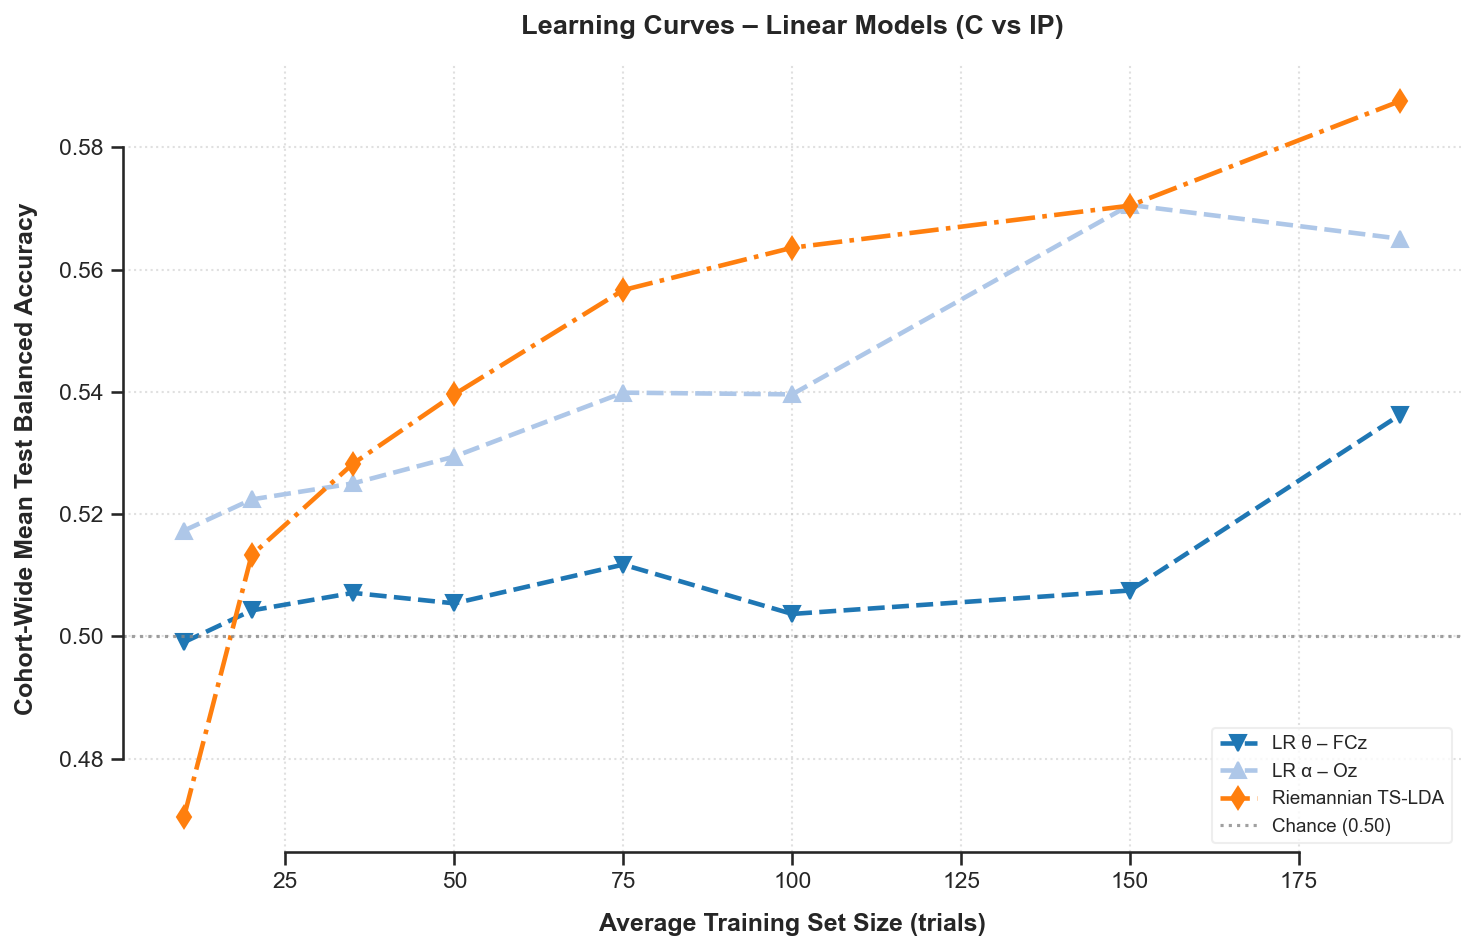

In [47]:
MODEL_COLORS_LC = {
    "LR_theta": "#1f77b4",
    "LR_alpha": "#aec7e8",
    "Riemann": "#ff7f0e",
}
MODEL_LABELS_LC = {
    "LR_theta": "LR θ – FCz",
    "LR_alpha": "LR α – Oz",
    "Riemann": "Riemannian TS-LDA",
}
MARKERS_LC = {
    "LR_theta": "v",
    "LR_alpha": "^",
    "Riemann": "d",
}
LINESTYLES_LC = {
    "LR_theta": "--",
    "LR_alpha": "--",
    "Riemann": "-.",
}
MODEL_ORDER_LC = [
    "LR_theta",
    "LR_alpha",
    "Riemann",
]


# ── helpers ────────────────────────────────────────────────────────────────────
def try_load_csv(*candidates):
    for p in candidates:
        if Path(p).exists():
            return pd.read_csv(p)
    return None


curves = {}  # model_name -> (x_arr, y_arr)

# ── 1. Load Riemann grid (also gives subject trial counts) ───────────────────
task_base = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
task_prefix_lc = "c_vs_i" if task_base == "c_vs_ip" else "im_vs_ip"
df_rie = try_load_csv(
    paths.analysis_root / riemann_dir / "tables" / "epochs_grid_riemann.csv",
    paths.analysis_root / riemann_dir / "tables" / f"epochs_grid_{task_prefix_lc}_riemann.csv",
)
if df_rie is not None:
    subject_trials_lc = df_rie.groupby("subject")["n_epochs_total"].max().to_dict()
    df_rie["train_trials"] = 0.5 * df_rie["n_epochs_total"]
    rie_curve = df_rie.groupby("n_epochs_total")[["train_trials", "acc_real_mean"]].mean().reset_index()
    if not rie_curve.empty:
        curves["Riemann"] = (rie_curve["train_trials"].values, rie_curve["acc_real_mean"].values)
else:
    subject_trials_lc = {}
    print("[SKIP] Riemann CSV not found")

# ── 2. LR epochs grid ────────────────────────────────────────────────────────
df_lr = try_load_csv(
    paths.analysis_root / lr_dir / "tables" / f"epochs_grid_{task_prefix_lc}_FCz_theta_Oz_alpha.csv",
)
if df_lr is not None:
    df_lr["train_trials"] = 0.5 * df_lr["n_epochs_total"]
    for elec, mname in [("FCz-theta", "LR_theta"), ("Oz-alpha", "LR_alpha")]:
        sub = (
            df_lr[df_lr["electrode"] == elec]
            .groupby("n_epochs_total")[["train_trials", "acc_real_mean"]]
            .mean()
            .reset_index()
        )
        if not sub.empty:
            curves[mname] = (sub["train_trials"].values, sub["acc_real_mean"].values)
else:
    print("[SKIP] LR CSV not found")


# ── 3. Plot ──────────────────────────────────────────────────────────────────────────
if not curves:
    print("[INFO] No learning curve data available yet.")
else:
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(10, 6.5), dpi=150)

    for mname in MODEL_ORDER_LC:
        if mname not in curves:
            continue
        x_vals, y_vals = curves[mname]
        ax.plot(
            x_vals,
            y_vals,
            LINESTYLES_LC[mname],
            marker=MARKERS_LC[mname],
            color=MODEL_COLORS_LC[mname],
            linewidth=2.2,
            markersize=7.5,
            label=MODEL_LABELS_LC[mname],
        )

    ax.axhline(0.5, color="#888", linestyle=":", linewidth=1.5, alpha=0.8, label="Chance (0.50)")
    ax.set_xlabel("Average Training Set Size (trials)", fontsize=12, fontweight="bold", labelpad=10)
    ax.set_ylabel("Cohort-Wide Mean Test Balanced Accuracy", fontsize=12, fontweight="bold", labelpad=10)
    ax.set_title(f"Learning Curves – Linear Models ({task_base.split('_vs_')[0].upper()} vs {task_base.split('_vs_')[1].upper()})", fontsize=13, fontweight="bold", pad=15)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#eaeaea", fontsize=9)
    sns.despine(trim=True)
    fig.tight_layout()

    out_path = paths.figures_dir / f"cohort_learning_curves_comparison_{TASK_TAG}.png"
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.show()

## Summary Metrics & Model Ranking Table

We calculate key summary statistics (Mean, Std Dev, Min, Max, Median) for each configuration and rank them by mean balanced accuracy.

In [36]:
summary_rows = []
for col in model_cols:
    vals = df_merged[col].values
    summary_rows.append(
        {
            "Model": col,
            "Mean Balanced Accuracy": np.mean(vals),
            "Std Dev": np.std(vals),
            "Median": np.median(vals),
            "Min": np.min(vals),
            "Max": np.max(vals),
        }
    )

df_summary = pd.DataFrame(summary_rows).sort_values(by="Mean Balanced Accuracy", ascending=False).reset_index(drop=True)
df_summary["Rank"] = df_summary.index + 1

summary_table_path = paths.tables_dir / f"cohort_cross_model_summary_{TASK_TAG}.csv"
df_summary.to_csv(summary_table_path, index=False)
print(f"Saved summary ranking table to: {summary_table_path}")
print("\n=== Model Ranking Summary ===")
df_summary

Saved summary ranking table to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\tables\cohort_cross_model_summary_c_vs_ip.csv

=== Model Ranking Summary ===


,Model,Mean Balanced Accuracy,Std Dev,Median,Min,Max,Rank
0,EEGNet_Agnostic,0.672856,0.096207,0.665935,0.462798,0.856507,1
1,Riemann,0.563746,0.066197,0.563167,0.453673,0.728696,2
2,Experiment_Guided,0.556603,0.075239,0.564417,0.415179,0.728745,3
3,SVC_Clustering,0.552732,0.047557,0.555018,0.451772,0.634965,4
4,LR_alpha,0.534856,0.051752,0.536075,0.418333,0.632576,5
5,ST_GNN,0.522614,0.050664,0.522452,0.429749,0.635417,6
6,LR_theta,0.499984,0.052881,0.504039,0.371212,0.586667,7
7,EEGNet_Clustering,0.496651,0.054689,0.507649,0.417132,0.610983,8
8,ST_EEGFormer,0.489440,0.051440,0.480011,0.375000,0.592796,9
9,LaBraM,0.486396,0.043032,0.490345,0.372347,0.543179,10


## Final Test-Set Summary Table

This table is built only from the reserved final holdout set. Classical baselines are evaluated here with fixed, pre-declared configurations. Deep-learning rows are loaded only from the `final_holdout_*.csv` files produced by each model notebook's `Final Holdout ONCE` cell; missing DL holdout files are marked as missing rather than replaced by CV estimates.

In [37]:
from scipy.signal import hilbert
from mne.filter import filter_data
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

FINAL_HOLDOUT_FRAC = 0.20
FINAL_MODEL_ORDER = [
    "LR_theta",
    "LR_alpha",
    "Riemann",
    "Experiment_Guided",
    "EEGNet_Agnostic",
    "EEGNet_Clustering",
    "SVC_Clustering",
    "ST_GNN",
    "ST_EEGFormer",
    "LaBraM",
]


def dev_holdout_idx(n, holdout_frac=FINAL_HOLDOUT_FRAC):
    cutoff = int(np.floor((1.0 - holdout_frac) * n))
    cutoff = max(1, min(cutoff, n - 1))
    return np.arange(cutoff), np.arange(cutoff, n)


def metric_row(model, subject, y_true, y_pred, y_score, *, source):
    try:
        auc_val = roc_auc_score(y_true, y_score)
    except ValueError:
        auc_val = np.nan
    return {
        "Task": TASK_TAG,
        "Model": model,
        "Subject": subject,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "ROC AUC": auc_val,
        "N Test": len(y_true),
        "Source": source,
        "Status": "ok",
    }


def regularize_spd_matrices(mats, eps=1e-5):
    mats = np.asarray(mats, dtype=np.float64)
    mats = np.nan_to_num(mats, nan=0.0, posinf=0.0, neginf=0.0)
    mats = 0.5 * (mats + np.swapaxes(mats, -1, -2))
    out = np.empty_like(mats)
    eye = np.eye(mats.shape[-1], dtype=np.float64)
    for i, mat in enumerate(mats):
        eigvals, eigvecs = np.linalg.eigh(mat + eps * eye)
        eigvals = np.maximum(eigvals, eps)
        repaired = (eigvecs * eigvals) @ eigvecs.T
        out[i] = 0.5 * (repaired + repaired.T)
    return out


def compute_lr_holdout_rows():
    spec = RawEpochSpec(
        picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0, analysis_window=(0.0, 1.5), peak_align_all_channels=True
    )
    ds = load_raw_epoch_dataset(paths, task, spec, verbose=False)
    X_raw = np.asarray(ds.X, dtype=np.float32)
    y_all = np.asarray(ds.y, dtype=np.int64)
    subj_all = np.asarray(ds.subjects, dtype=object)
    chs = list(ds.channel_names)
    times = np.asarray(ds.times)
    configs = {
        "LR_theta": {"channel": "FCz", "band": (5.0, 7.0), "window": (0.5, 1.0)},
        "LR_alpha": {"channel": "Oz", "band": (8.0, 12.0), "window": (0.5, 1.0)},
    }
    rows = []
    for sub in pd.unique(subj_all):
        mask = subj_all == sub
        y_sub = y_all[mask]
        dev_idx, hold_idx = dev_holdout_idx(len(y_sub))
        if len(np.unique(y_sub[dev_idx])) < 2 or len(np.unique(y_sub[hold_idx])) < 2:
            continue
        for model, cfg in configs.items():
            if cfg["channel"] not in chs:
                continue
            ch_idx = chs.index(cfg["channel"])
            t_mask = (times >= cfg["window"][0]) & (times <= cfg["window"][1])
            X_ch = X_raw[mask][:, [ch_idx], :]
            X_filt = filter_data(
                X_ch.astype(np.float64),
                sfreq=128.0,
                l_freq=cfg["band"][0],
                h_freq=cfg["band"][1],
                method="iir",
                verbose=False,
            )
            feats = np.abs(hilbert(X_filt[..., t_mask], axis=-1)).mean(axis=(1, 2))[:, None]
            clf = make_pipeline(
                StandardScaler(),
                LogisticRegression(C=1.0, penalty="l2", class_weight="balanced", max_iter=1000, random_state=42),
            )
            clf.fit(feats[dev_idx], y_sub[dev_idx])
            pred = clf.predict(feats[hold_idx])
            score = clf.predict_proba(feats[hold_idx])[:, 1]
            rows.append(metric_row(model, sub, y_sub[hold_idx], pred, score, source="computed_final_holdout"))
    return rows


def compute_riemann_holdout_rows():
    spec = RawEpochSpec(
        picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0, analysis_window=(0.0, 1.5), peak_align_all_channels=True
    )
    ds = load_raw_epoch_dataset(paths, task, spec, verbose=False)
    X_raw = np.asarray(ds.X, dtype=np.float32)
    y_all = np.asarray(ds.y, dtype=np.int64)
    subj_all = np.asarray(ds.subjects, dtype=object)
    chs = list(ds.channel_names)
    times = np.asarray(ds.times)
    theta_chs = [ch for ch in TARGET_BANDS_CLUSTERS["theta"] if ch in chs]
    alpha_chs = [ch for ch in TARGET_BANDS_CLUSTERS["alpha"] if ch in chs]
    theta_idx = [chs.index(ch) for ch in theta_chs]
    alpha_idx = [chs.index(ch) for ch in alpha_chs]
    t_mask = (times >= 0.0) & (times <= 1.5)
    rows = []
    for sub in pd.unique(subj_all):
        mask = subj_all == sub
        y_sub = y_all[mask]
        dev_idx, hold_idx = dev_holdout_idx(len(y_sub))
        if len(np.unique(y_sub[dev_idx])) < 2 or len(np.unique(y_sub[hold_idx])) < 2:
            continue
        X_sub = X_raw[mask]
        X_theta = filter_data(
            X_sub[:, theta_idx][..., t_mask].astype(np.float64),
            sfreq=128.0,
            l_freq=5.0,
            h_freq=7.0,
            method="iir",
            verbose=False,
        )
        X_alpha = filter_data(
            X_sub[:, alpha_idx][..., t_mask].astype(np.float64),
            sfreq=128.0,
            l_freq=8.0,
            h_freq=12.0,
            method="iir",
            verbose=False,
        )
        X_fused = np.concatenate([X_theta, X_alpha], axis=1)
        cov = Covariances(estimator="oas")
        X_dev_cov = regularize_spd_matrices(cov.fit_transform(X_fused[dev_idx]))
        X_hold_cov = regularize_spd_matrices(cov.transform(X_fused[hold_idx]))
        ts = TangentSpace(metric="riemann")
        X_dev_ts = ts.fit_transform(X_dev_cov, y_sub[dev_idx])
        X_hold_ts = ts.transform(X_hold_cov)
        clf = LDA(solver="lsqr", shrinkage="auto")
        clf.fit(X_dev_ts, y_sub[dev_idx])
        pred = clf.predict(X_hold_ts)
        score = clf.predict_proba(X_hold_ts)[:, 1]
        rows.append(metric_row("Riemann", sub, y_sub[hold_idx], pred, score, source="computed_final_holdout"))
    return rows


def load_final_holdout_csv(model, path):
    if not path.exists():
        return pd.DataFrame(
            [
                {
                    "Task": TASK_TAG,
                    "Model": model,
                    "Subject": np.nan,
                    "Accuracy": np.nan,
                    "Balanced Accuracy": np.nan,
                    "ROC AUC": np.nan,
                    "N Test": 0,
                    "Source": str(path),
                    "Status": "missing_final_holdout",
                }
            ]
        )
    df = pd.read_csv(path).copy()
    if "Model" not in df.columns:
        df["Model"] = model
    else:
        df["Model"] = df["Model"].replace({"ST-GNN": "ST_GNN", "ST-EEGFormer": "ST_EEGFormer"})
    df["Status"] = "ok"
    df["Source"] = str(path)
    return df


classical_file = paths.tables_dir / f"final_holdout_classical_baselines_{TASK_TAG}.csv"
if classical_file.exists():
    df_classical_final = pd.read_csv(classical_file)
else:
    classical_rows = compute_lr_holdout_rows() + compute_riemann_holdout_rows()
    df_classical_final = pd.DataFrame(classical_rows)
    df_classical_final.to_csv(classical_file, index=False)
    print("Saved classical final holdout baselines to:", classical_file)

if TASK_TAG == "c_vs_ip":
    final_sources = {
        "Experiment_Guided": paths.analysis_root
        / "experiment_guided_config_c_ip"
        / "tables"
        / "experiment_guided_config_c_ip_final_holdout_ONCE.csv",
        "EEGNet_Agnostic": paths.analysis_root / "eegnet" / "tables" / "final_holdout_c_vs_ip_eegnet.csv",
        "EEGNet_Clustering": paths.analysis_root / "eegnet" / "tables" / "final_holdout_c_vs_ip_eegnet.csv",
        "SVC_Clustering": paths.analysis_root
        / "svc_clustering"
        / "tables"
        / "svc_clustering_c_vs_ip_final_holdout_ONCE.csv",
        "ST_GNN": paths.analysis_root / "c_vs_i_stgnn" / "tables" / "final_holdout_c_vs_ip_stgnn.csv",
        "ST_EEGFormer": paths.analysis_root / "c_vs_i_steegformer" / "tables" / "final_holdout_c_vs_ip_steegformer.csv",
        "LaBraM": paths.analysis_root / "c_vs_i_labram" / "tables" / "final_holdout_c_vs_ip_labram.csv",
    }
else:
    final_sources = {
        "Experiment_Guided": paths.analysis_root
        / "experiment_guided_config_im_ip"
        / "tables"
        / "experiment_guided_config_im_ip_final_holdout_ONCE.csv",
        "EEGNet_Agnostic": paths.analysis_root / "eegnet_im_vs_ip" / "tables" / "final_holdout_im_vs_ip_eegnet.csv",
        "EEGNet_Clustering": paths.analysis_root / "eegnet_im_vs_ip" / "tables" / "final_holdout_im_vs_ip_eegnet.csv",
        "SVC_Clustering": paths.analysis_root
        / "svc_clustering"
        / "tables"
        / "svc_clustering_im_vs_ip_final_holdout_ONCE.csv",
        "ST_GNN": paths.analysis_root / "im_vs_ip_stgnn" / "tables" / "final_holdout_im_vs_ip_stgnn.csv",
        "ST_EEGFormer": paths.analysis_root
        / "im_vs_ip_steegformer"
        / "tables"
        / "final_holdout_im_vs_ip_steegformer.csv",
        "LaBraM": paths.analysis_root / "im_vs_ip_labram" / "tables" / "final_holdout_im_vs_ip_labram.csv",
    }

dfs = [df_classical_final]
for model, file_path in final_sources.items():
    df_model = load_final_holdout_csv(model, file_path)
    if model.startswith("EEGNet") and "Model" in df_model.columns:
        df_model = df_model[df_model["Model"] == model]
        if df_model.empty:
            df_model = load_final_holdout_csv(model, Path("missing_eegnet_variant.csv"))
    elif model == "Experiment_Guided":
        df_model["Model"] = "Experiment_Guided"
    dfs.append(df_model)

df_final_test = pd.concat(dfs, ignore_index=True)
summary_rows = []
for model in FINAL_MODEL_ORDER:
    d = df_final_test[(df_final_test["Model"] == model) & (df_final_test["Status"] == "ok")].copy()
    if d.empty:
        status = (
            df_final_test.loc[df_final_test["Model"] == model, "Status"].iloc[0]
            if (df_final_test["Model"] == model).any()
            else "missing_final_holdout"
        )
        summary_rows.append(
            {
                "Model": model,
                "Accuracy Mean": np.nan,
                "Accuracy SD": np.nan,
                "Accuracy ± SD": "missing",
                "Balanced Accuracy ± SD": "missing",
                "ROC AUC Mean": np.nan,
                "N Subjects": 0,
                "N Test Trials": 0,
                "Status": status,
            }
        )
        continue
    summary_rows.append(
        {
            "Model": model,
            "Accuracy ± SD": f"{d['Accuracy'].mean() * 100:.1f} ± {d['Accuracy'].std() * 100:.1f}",
            "Balanced Accuracy ± SD": f"{d['Balanced Accuracy'].mean() * 100:.1f} ± {d['Balanced Accuracy'].std()*100:.1f}",
            "ROC AUC Mean": d["ROC AUC"].mean(),
            "N Subjects": d["Subject"].nunique(),
            "N Test Trials": int(d["N Test"].sum()),
            "Status": "ok",
        }
    )

df_final_summary = pd.DataFrame(summary_rows)
summary_path = paths.tables_dir / f"final_test_set_summary_{TASK_TAG}.csv"
detail_path = paths.tables_dir / f"final_test_set_subject_details_{TASK_TAG}.csv"
df_final_summary.to_csv(summary_path, index=False)
df_final_test.to_csv(detail_path, index=False)
print("Final test-set summary saved to:", summary_path)
print("Subject-level details saved to:", detail_path)
display(df_final_summary)

Final test-set summary saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\tables\final_test_set_summary_c_vs_ip.csv
Subject-level details saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\tables\final_test_set_subject_details_c_vs_ip.csv


,Model,Accuracy ± SD,Balanced Accuracy ± SD,ROC AUC Mean,N Subjects,N Test Trials,Status
0,LR_theta,50.9 ± 6.2,49.6 ± 6.7,0.509499,24,1184,ok
1,LR_alpha,54.5 ± 9.1,53.6 ± 8.2,0.546427,24,1184,ok
2,Riemann,58.8 ± 9.3,58.7 ± 8.3,0.618914,24,1184,ok
3,Experiment_Guided,57.8 ± 9.4,56.9 ± 8.1,0.612438,24,1184,ok
4,EEGNet_Agnostic,53.2 ± 9.9,53.2 ± 8.2,0.549826,24,1184,ok
5,EEGNet_Clustering,50.4 ± 9.2,49.6 ± 8.0,0.490318,24,1184,ok
6,SVC_Clustering,56.8 ± 8.0,56.2 ± 6.3,0.583536,24,1184,ok
7,ST_GNN,53.1 ± 10.3,52.0 ± 7.3,0.550305,24,1184,ok
8,ST_EEGFormer,52.5 ± 12.6,52.5 ± 8.3,0.538021,24,1184,ok
9,LaBraM,52.6 ± 10.3,51.9 ± 6.8,0.538478,24,1184,ok
